In [1]:
from cotree import *
import torch
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


if torch.cuda.is_available():
    # Get the current GPU device
    current_device = torch.cuda.current_device()
    print("Current GPU Device:", torch.cuda.get_device_name(current_device))
else:
    print("CUDA is not available. No GPU detected.")

Using device: cuda
Current GPU Device: NVIDIA RTX 6000 Ada Generation


/home/slwgroup/anaconda3/envs/cotree/lib/python3.12/site-packages/torch/cuda/__init__.py:827: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")


# Data preprocessing

In [3]:
# Load example data
# For other data, run 
    # data_folder = './data' (path)
    # file_name = ['Multi_Replication'] (replace by sub folder name)
    # dataset = OmicsDataset(data_folder, file_name) 

from importlib.resources import files, as_file

data_traversable = files("cotree.data")

with as_file(data_traversable) as data_dir_path:
    file_name = ["Multi_Replication"]
    dataset = OmicsDataset(data_dir_path, file_name)

Loading datasets:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Multi_Replication, Loading files in genomics: 100%|██████████| 50/50 [00:00<00:00, 253.75it/s]
Processing Multi_Replication, Loading files in transcriptomics: 100%|██████████| 50/50 [00:00<00:00, 265.51it/s]
Processing Multi_Replication, Loading files in proteomics: 100%|██████████| 50/50 [00:00<00:00, 213.94it/s]
Processing Multi_Replication, Loading files in metabolomics: 100%|██████████| 50/50 [00:00<00:00, 377.93it/s]
Preparing samples: 100%|██████████| 50/50 [00:00<00:00, 3492.05it/s]


In [4]:
# Remove cytoplasmic form of membrane protein species
filter_protein_index = [i for i,p in enumerate(dataset.names["proteomics"]) if p.startswith("C_")]
filter_index = {"G":[], "M":[], "P": filter_protein_index, "R":[]}

# load data
training_data = training_dataset(dataset.samples, filter_index)
total_samples = training_data.__len__()

In [5]:
# Remove species names for invariant metabolites and protein
dataset.names["metabolomics"] = dataset.names["metabolomics"][training_data.keep_ind['M']]
dataset.names["proteomics"] = dataset.names["proteomics"][training_data.keep_ind['P']]
dataset.names["genomics"] = dataset.names["genomics"][training_data.keep_ind['G']]
dataset.names["transcriptomics"] = dataset.names["transcriptomics"][training_data.keep_ind['R']]


# name of species
species = list(dataset.names['genomics'])+list(dataset.names['metabolomics'])+list(dataset.names['proteomics'])


# print species number
for key,val in dataset.names.items():
    print(f"Species in {key}: {len(val)}")

Species in genomics: 493
Species in transcriptomics: 455
Species in proteomics: 458
Species in metabolomics: 181


# Representation Learning

In [6]:
# autoencoder parameters for G M P R 
input_size = {'M':181, 'P':458, 'R':455, 'G':493} 
hidden_layer_encoder = {'M':[100], 'P':[250], 'R':[250], 'G':[100]}
latent_dim = {'M':30, 'P':50, 'G':10, "R": 455}
hidden_layer_decoder = {'M': [100], 'P': [250], 'G': [100]}
hidden_layer_predictor = {'M': [100], 'P': [250], 'G': [100]}

In [7]:
RL_model = train_autoencoder_model(training_data,
                                    device,
                                    input_size = input_size,
                                    hidden_layer_encoder = hidden_layer_encoder,
                                    hidden_layer_decoder = hidden_layer_decoder,
                                    hidden_layer_predictor = hidden_layer_predictor,
                                    latent_dim = latent_dim,
                                    epochs = 200,
                                    batch_size = 200,
                                    lr  = 5e-3,
                                    step_size = 200,
                                    gamma = 0.5,
                                    weight_curr ={"G": 2.0, "M": 1.0, "P": 2.0},  # weights for current loss
                                    weight_pred = {"G": 2.0, "M": 1.0, "P": 2.0},  # weights for future/pred loss
                                    print_every = 10,
                                    dropout_rate = 0,
                                    ratio_train_test = 0.99
                                    )

Training: 100%|██████████| 200/200 [00:23<00:00,  8.43it/s, train_loss=0.1320, val_loss=0.1552, lr=2.500e-03] 


In [8]:
# Get data for inference
output_data = RL_output(RL_model, dataset, training_data, training_data.keep_ind, device)
latent_embedding = output_data['Latent representation']
M_stack = output_data['Raw metabolite']
P_stack = output_data['Raw protein']
G_stack = output_data['Raw gene']

print(f"Number of latent features: {latent_embedding.shape[1]}")

Number of latent features: 90


In [9]:
# Concatenated data of gene, metabolite and protein

data_raw = np.concatenate((G_stack,M_stack,P_stack),axis = -1)

# Functional module detection

In [10]:
# Estimate functional module
# Higher cosine value indicates a more accurate estimation
# Increasing epoch number for better results
latent_size = latent_dim['G']+latent_dim['P']+latent_dim['M']
f_vector = np.zeros((latent_size,input_size['G']+input_size['M']+input_size['P']))
for index in range(latent_size):
    f_vector[index] = function_module_estimation(RL_model, training_data, index, lambda_reg=0.001, input_size = input_size, device = device, learning_rate=0.01, 
                 epochs=10)

Index 0 for functional model 1,Mean Cosine: 0.922870, Reg: 0.033224
Index 1 for functional model 2,Mean Cosine: 0.074446, Reg: 0.018948
Index 2 for functional model 3,Mean Cosine: 0.103763, Reg: 0.031791
Index 3 for functional model 4,Mean Cosine: 0.948521, Reg: 0.055407
Index 4 for functional model 5,Mean Cosine: 0.023726, Reg: 0.009949
Index 5 for functional model 6,Mean Cosine: 0.760323, Reg: 0.040044
Index 6 for functional model 7,Mean Cosine: 0.889343, Reg: 0.045488
Index 7 for functional model 8,Mean Cosine: 0.712038, Reg: 0.032651
Index 8 for functional model 9,Mean Cosine: 0.028908, Reg: 0.017848
Index 9 for functional model 10,Mean Cosine: 0.016471, Reg: 0.011207
Index 10 for functional model 11,Mean Cosine: 0.302346, Reg: 0.036752
Index 11 for functional model 12,Mean Cosine: 0.939459, Reg: 0.017603
Index 12 for functional model 13,Mean Cosine: 0.925492, Reg: 0.014766
Index 13 for functional model 14,Mean Cosine: 0.942412, Reg: 0.016388
Index 14 for functional model 15,Mean C

In [11]:
# Find species
functional_module = {}

for i in range(f_vector.shape[0]):
    index = functional_module_species(G_stack,M_stack,P_stack,f_vector[i],RL_model,[i],input_size, device)
    functional_module[f'Functional Module {i+1}'] = np.array(species)[index]

Functional Module: 1 Finished.
Functional Module: 2 Finished.
Functional Module: 3 Finished.
Functional Module: 4 Finished.
Functional Module: 5 Finished.
Functional Module: 6 Finished.
Functional Module: 7 Finished.
Functional Module: 8 Finished.
Functional Module: 9 Finished.
Functional Module: 10 Finished.
Functional Module: 11 Finished.
Functional Module: 12 Finished.
Functional Module: 13 Finished.
Functional Module: 14 Finished.
Functional Module: 15 Finished.
Functional Module: 16 Finished.
Functional Module: 17 Finished.
Functional Module: 18 Finished.
Functional Module: 19 Finished.
Functional Module: 20 Finished.
Functional Module: 21 Finished.
Functional Module: 22 Finished.
Functional Module: 23 Finished.
Functional Module: 24 Finished.
Functional Module: 25 Finished.
Functional Module: 26 Finished.
Functional Module: 27 Finished.
Functional Module: 28 Finished.
Functional Module: 29 Finished.
Functional Module: 30 Finished.
Functional Module: 31 Finished.
Functional Module

In [12]:
# Example of functional module

functional_module['Functional Module 16']

array(['M_udpg_c', 'M_ap_c', 'M_pa_c', 'M_glyc_c', 'M_glyc3p_c',
       'M_1ag3p_c', 'M_cdpdag_c', 'M_pg3p_c', 'M_pg_c', 'M_12dgr_c',
       'M_udpgalfur_c', 'M_fa_c', 'M_tag_c', 'M_cmp_c', 'M_ctp_c',
       'M_dcdp_c', 'M_gsn_c', 'M_gmp_c', 'M_dgmp_c', 'M_ura_c', 'M_uri_c',
       'M_ump_c', 'M_udp_c', 'M_adn_c', 'M_ade_c', 'M_dadp_c',
       'M_thymd_c', 'M_dtmp_c', 'M_dttp_c', 'M_glu__L_c', 'M_g1p_c',
       'M_amp_c', 'M_adp_c', 'M_10fthfglu3_c', 'M_nh3_c', 'M_pep_c',
       'M_pyr_c', 'M_xu5p__D_c', 'M_ru5p__D_c', 'M_prpp_c', 'M_e4p_c',
       'M_r1p_c', 'M_fdp_c', 'M_s7p_c', 'M_g3p_c', 'M_2dr5p_c', 'M_nad_c',
       'M_nadh_c', 'M_13dpg_c', 'M_nadp_c', 'M_nadph_c', 'M_3pg_c',
       'M_2pg_c', 'M_accoa_c', 'M_acald_c', 'M_dnad_c', 'M_ribflv_c',
       'M_fmn_c', 'M_pydx5p_c', 'M_ala__L_c', 'M_arg__L_c', 'M_asn__L_c',
       'M_asp__L_c', 'M_gly_c', 'M_ile__L_c', 'M_leu__L_c', 'M_lys__L_c',
       'M_met__L_c', 'M_phe__L_c', 'M_pro__L_c', 'M_ser__L_c',
       'M_thr__L_c', 'M_trp_

Estimation of importance score:

In [13]:
latent_size = latent_dim['G']+latent_dim['P']+latent_dim['M']
importance_score = np.zeros((latent_size,input_size['G']+input_size['M']+input_size['P']))
for index in range(latent_size):
    importance_score[index] = function_score_estimation(RL_model, index, dataset, latent_dim, training_data.scale_meta, 
                             training_data.scale_protein, 
                             training_data.scale_dna, 
                             training_data.scale_rna, 
                             training_data.keep_ind, device)
    print(f'Latent dim {index+1} finished.')

Latent dim 1 finished.
Latent dim 2 finished.
Latent dim 3 finished.
Latent dim 4 finished.
Latent dim 5 finished.
Latent dim 6 finished.
Latent dim 7 finished.
Latent dim 8 finished.
Latent dim 9 finished.
Latent dim 10 finished.
Latent dim 11 finished.
Latent dim 12 finished.
Latent dim 13 finished.
Latent dim 14 finished.
Latent dim 15 finished.
Latent dim 16 finished.
Latent dim 17 finished.
Latent dim 18 finished.
Latent dim 19 finished.
Latent dim 20 finished.
Latent dim 21 finished.
Latent dim 22 finished.
Latent dim 23 finished.
Latent dim 24 finished.
Latent dim 25 finished.
Latent dim 26 finished.
Latent dim 27 finished.
Latent dim 28 finished.
Latent dim 29 finished.
Latent dim 30 finished.
Latent dim 31 finished.
Latent dim 32 finished.
Latent dim 33 finished.
Latent dim 34 finished.
Latent dim 35 finished.
Latent dim 36 finished.
Latent dim 37 finished.
Latent dim 38 finished.
Latent dim 39 finished.
Latent dim 40 finished.
Latent dim 41 finished.
Latent dim 42 finished.
L

Plot of the average score of all the genes:

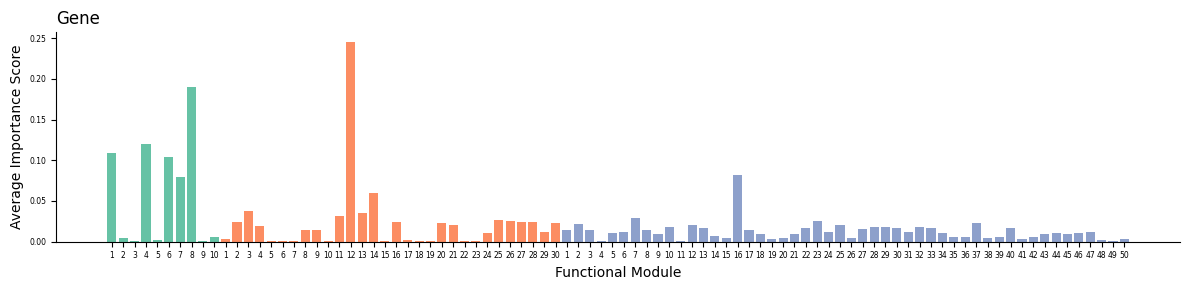

In [14]:
# Example plot of importance score to gene
gene_score = np.mean(importance_score[:,:input_size['G']],axis=1)
np.argsort(gene_score)[::-1]

modules = [f"{i+1}" for i in range(len(gene_score))]
modules_x = [i for i in range(1,11)]+[i for i in range(1,31)]+[i for i in range(1,51)]

# Define colors for each range
color_a = sns.color_palette("Set2")[0]  # first 10
color_b = sns.color_palette("Set2")[1]  # 11–40
color_c = sns.color_palette("Set2")[2]  # 41+

# Assign colors based on module index
colors = []
for i in range(len(gene_score)):
    if i < 10:
        colors.append(color_a)
    elif i < 40:
        colors.append(color_b)
    else:
        colors.append(color_c)

fig, ax = plt.subplots(figsize=(12, 3))
ax.bar(modules, gene_score, color=colors)

ax.set_xlabel("Functional Module", fontsize=10)
ax.set_ylabel("Average Importance Score", fontsize=10)
ax.set_title("Gene", fontsize=12, loc='left', pad=6)
ax.tick_params(axis='both', labelsize=5.5)
ax.set_xticks(range(len(modules)))
ax.set_xticklabels(modules_x)
sns.despine()

# Save and show
plt.tight_layout()
plt.show()

Plot of the average score of all the metabolite:

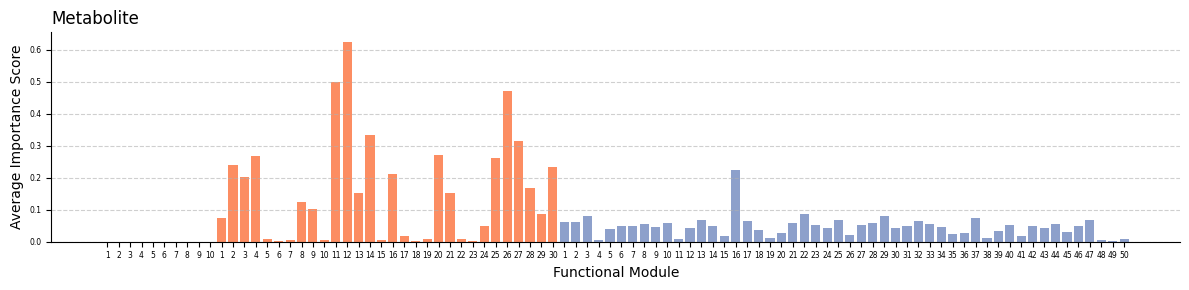

In [15]:
# importance score to metabolite
meta_score = np.mean(importance_score[:,(input_size['G']):(input_size['G']+input_size['M'])],axis=1)
fig, ax = plt.subplots(figsize=(12, 3))
ax.bar(modules, meta_score, color=colors)

# Labels and style
ax.set_xlabel("Functional Module", fontsize=10)
ax.set_ylabel("Average Importance Score", fontsize=10)
ax.set_title("Metabolite", fontsize=12, loc='left', pad=6)
ax.grid(True, linestyle='--', alpha=0.6, axis='y')
ax.tick_params(axis='both', labelsize=5.5)
ax.set_xticks(range(len(modules)))
ax.set_xticklabels(modules_x)
sns.despine()

# Save and show
plt.tight_layout()
plt.show()

Plot of the average score of protein:

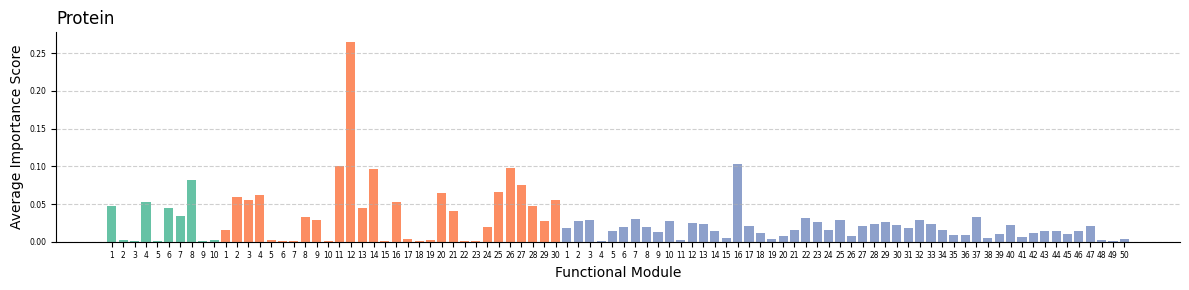

In [16]:
# importance score to protein
protein_score = np.mean(importance_score[:(input_size['G']+input_size['M']+input_size['P']):],axis=1)
np.argsort(protein_score)[::-1]

modules = [f"{i+1}" for i in range(len(protein_score))]

fig, ax = plt.subplots(figsize=(12, 3))
ax.bar(modules, protein_score, color=colors)

# Labels and style
ax.set_xlabel("Functional Module", fontsize=10)
ax.set_ylabel("Average Importance Score", fontsize=10)
ax.set_title("Protein", fontsize=12, loc='left', pad=6)
ax.grid(True, linestyle='--', alpha=0.6, axis='y')
ax.tick_params(axis='both', labelsize=5.5)
ax.set_xticks(range(len(modules)))
ax.set_xticklabels(modules_x)
sns.despine()

# Save and show
plt.tight_layout()
plt.show()

# Construct trajectory tree.

In [17]:
cell_num = 50 # Number of cells
time_length = 106 # Number of time points

cell_embeddings = latent_embedding.reshape(-1, time_length, latent_embedding.shape[1])

In [18]:
trajectory_tree, bifurcation_point, sepration_time = construct_principal_tree(latent_embedding, 
                                                                                time_length, 
                                                                                cell_num, 
                                                                                max_iter = 20, 
                                                                                span = 0.75,
                                                                                epsilon = 0.1, 
                                                                                n_clusters_before = 5,
                                                                                n_clusters_after = 3,
                                                                                project_diff = 0.25,
                                                                                alpha=0.05)

In [19]:
# Project cells to the tree
growth_stage_matrix, projection_distances, segment__d, total_d = project_embeddings_to_tree(latent_embedding,
                                                                                    trajectory_tree,
                                                                                    time_length, stretch=0, project_diff=0)
# Clustering
clustering_label = lineage_clustering(projection_distances, time_length, trajectory_tree)
clustering_label_all = np.array([item for item in clustering_label for _ in range(time_length)])

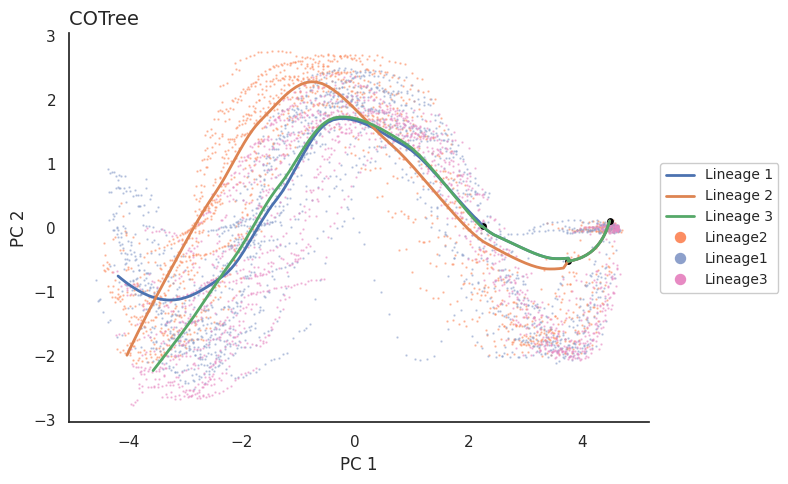

In [20]:
# Visualize the tree
vis_tree(latent_embedding, trajectory_tree, clustering_label_all, bifurcation_point, save_path=None)

Tree for single omics:

In [21]:
latent_embedding_G, latent_embedding_M, latent_embedding_P, _ = seperate_output(latent_embedding, latent_dim)
bifurcation_point_G, bifurcation_point_M, bifurcation_point_P, _ = seperate_output(bifurcation_point, latent_dim)
trajectory_tree_M = {}
trajectory_tree_P = {}
for leaf, lineage in trajectory_tree.items():
    _,trajectory_tree_M[leaf],trajectory_tree_P[leaf],_ = seperate_output(trajectory_tree[leaf], latent_dim)

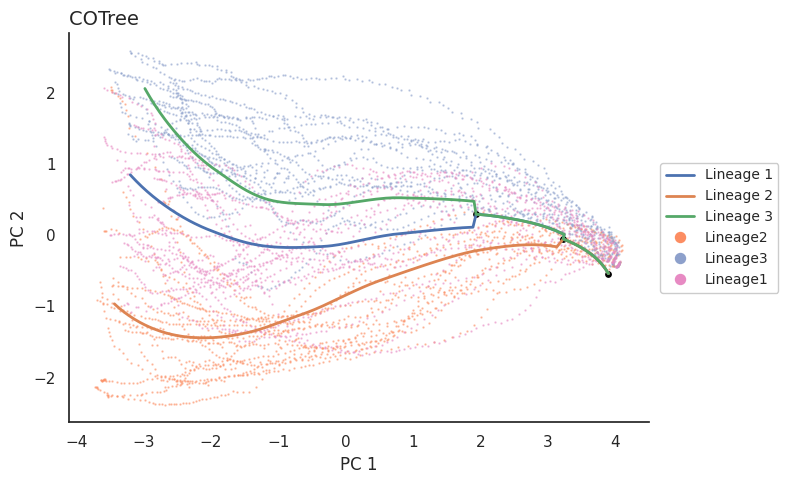

In [22]:
# Metabolite tree
growth_stage_matrix_M, projection_d_M, segment__d_M, total_d_M = project_embeddings_to_tree(latent_embedding_M,
                                                                                    trajectory_tree_M,
                                                                                    time_length, stretch=0, project_diff=0)
clustering_label_M = lineage_clustering(projection_d_M, time_length, trajectory_tree_M)
clustering_label_M_all = np.array([item for item in clustering_label_M for _ in range(time_length)])
vis_tree(latent_embedding_M, trajectory_tree_M, clustering_label_M_all, bifurcation_point_M, save_path=None)

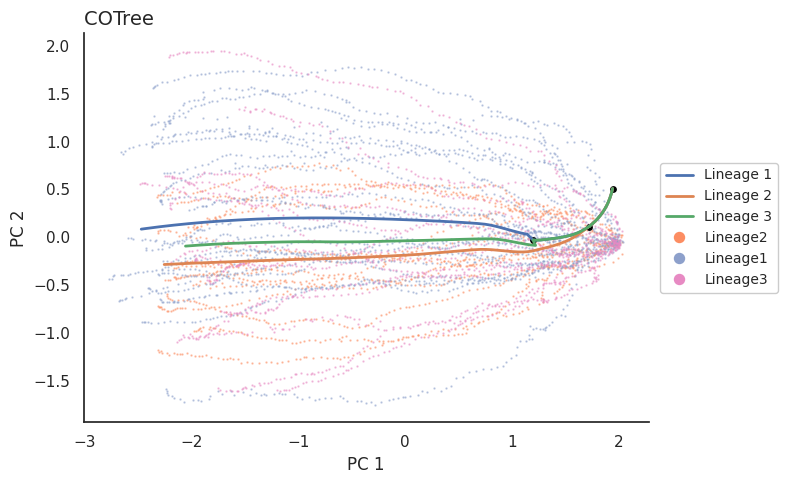

In [23]:
# Protein tree
growth_stage_matrix_P, projection_d_P, segment__d_P, total_d_P = project_embeddings_to_tree(latent_embedding_P,
                                                                                    trajectory_tree_P,
                                                                                    time_length, stretch=0, project_diff=0)
clustering_label_P = lineage_clustering(projection_d_P, time_length, trajectory_tree_P)
clustering_label_P_all = np.array([item for item in clustering_label_P for _ in range(time_length)])
vis_tree(latent_embedding_P, trajectory_tree_P, clustering_label_P_all, bifurcation_point_P, save_path=None)

# Predictive time and retrospective time

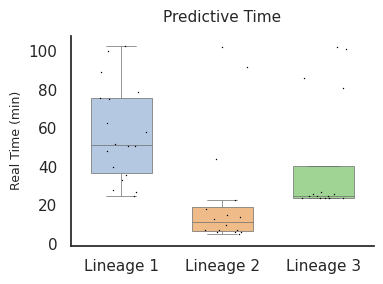

In [24]:
predictive_time_all = vis_predictive_time(trajectory_tree, projection_distances, clustering_label, time_length)

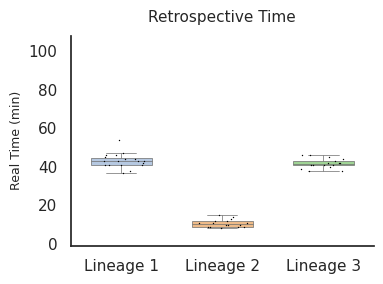

In [25]:
retrospective_time = vis_retrospective_time(trajectory_tree, growth_stage_matrix, sepration_time, clustering_label, time_length)

# Driver species detection

Seperation time for lineages:

In [26]:
sepration_time

{'Lineage1': np.float64(9.239028890197217),
 'Lineage3': np.float64(9.239028890197217),
 'Lineage2': np.float64(4.318241763896525)}

Prepare inputs for driver species detection:

In [27]:
cell_growth_stage_matrix = growth_stage_matrix.reshape(cell_num,time_length,-1)
cell_data_raw = data_raw.reshape(cell_num, time_length, -1)

In [28]:
raw_data, encoded_data, weight, real_time = extract_trajectory(trajectory_tree,
                                                                cell_growth_stage_matrix,
                                                                cell_data_raw,
                                                                cell_embeddings,
                                                                clustering_label,
                                                                sepration_time,
                                                                list_truncation=80,
                                                                inter = 10)

We detect driver species for the first bifurcation node, where Lineage 3 seperates from the other two lineages:

In [29]:
diff_score_node1, diff_species1 = driver_species_detection(RL_model,
                                  0, 
                                  raw_data, 
                                  encoded_data, 
                                  weight, 
                                  input_size,
                                  device,
                                  sparse_penalty = 0.01, 
                                  epoches = 300, 
                                  learning_rate = 0.001)

Training: 100%|██████████| 300/300 [00:01<00:00, 235.66it/s, Cosine (direction 1)=0.859059, Cosine (direction 2)=0.813219, regularization=0.104601]


tau:0.05339653417468071


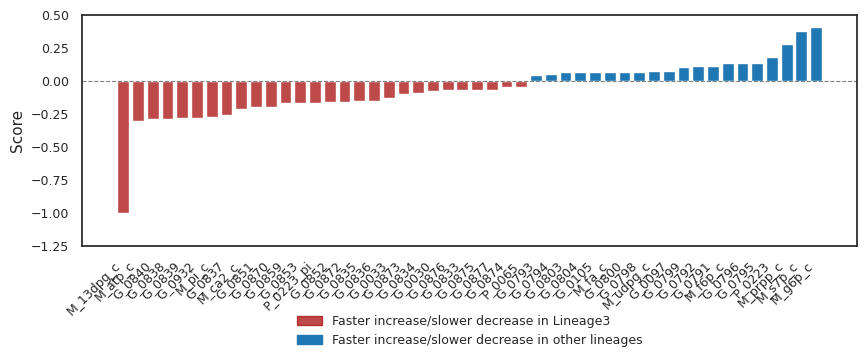

In [30]:
plot_species_scores(diff_score_node1, species, "Lineage3", diff_species1, figsize = (10,3))

Granger canusality among differential species

In [31]:
lineage_profiles = reconstruct_lineage(trajectory_tree, RL_model, latent_dim, device)

We detect granger causality between ppi, pi and G_0621 on Lineage 3. 

In [32]:
index_output_all = [551, 555, 0]
index_input_all = [551, 555, 0]
time_lag = 10
B_list = np.zeros((len(index_output_all),time_lag,len(index_input_all)))

In [33]:
for j in range(len(index_output_all)):
    for i in range(len(index_input_all)):    
        index_output_ind = [index_output_all[j]]
        index_input_ind = [index_input_all[i]]
        if index_output_all[j] != index_input_all[i]:
            B = train_causality_model(lineage_profiles['Lineage3'], index_output_ind, index_input_ind, device, time_lag = time_lag, l1_lambda = 2, 
                                                    lr = 0.01, 
                                                    batch_size = 45,
                                                    num_epochs = 500, differencing = False)
            
            B_list[j,:,i] = B.reshape(-1)

Training: 100%|██████████| 500/500 [00:04<00:00, 122.40it/s, MSE-Loss=0.0000, L1-Loss=0.0000]


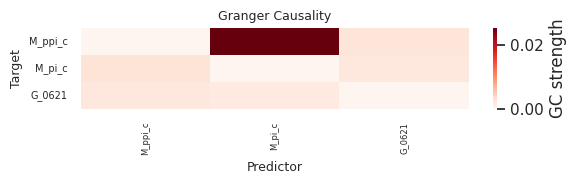

In [34]:
species_input = [species[i] for i in index_input_all]
species_output = [species[i] for i in index_output_all]
plot_gc_heatmap(
    B_list,
    x_labels=species_input,
    y_labels=species_output,
    figsize=(6,2),
    file_path=None
)